# 06 · Deep Neural Network (Maxout) benchmark (Fischer & Krauss, 2018)

## 1. Setup and configuration

In [1]:
import copy
import random
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore", category=FutureWarning)


PROJECT_ROOT_OVERRIDE = None


def find_project_root():
    """Walk up from the working directory until data/processed/price_panel.csv is found."""
    if PROJECT_ROOT_OVERRIDE is not None:
        return Path(PROJECT_ROOT_OVERRIDE)
    here = Path.cwd().resolve()
    for p in [here, *here.parents][:6]:
        if (p / "data" / "processed" / "price_panel.csv").exists():
            return p
    raise RuntimeError(
        f"Could not find data/processed/price_panel.csv starting from {Path.cwd()}. "
        "Set PROJECT_ROOT_OVERRIDE to your project folder.")


ROOT = find_project_root()
PROCESSED_DIR = ROOT / "data" / "processed"
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


TRAIN_DAYS = 750
TRADE_DAYS = 250
VALIDATION_FRACTION = 0.20


CUMULATIVE_RETURN_HORIZONS = list(range(1, 21)) + list(range(40, 241, 20))
assert len(CUMULATIVE_RETURN_HORIZONS) == 31, "Expected 31 horizons"
FEATURE_COLS = [f"ret_{m}d" for m in CUMULATIVE_RETURN_HORIZONS]


SEED = 42
N_INPUTS = len(FEATURE_COLS)          
HIDDEN_SIZES = [31, 10, 5]
MAXOUT_CHANNELS = 2
DROPOUT = 0.5
L1_LAMBDA = 1e-5


LEARNING_RATE = 1e-3
BATCH_SIZE = 256
MAX_EPOCHS = 200
PATIENCE = 10
MIN_DELTA = 1e-5

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


K_LONG_SHORT = 10
TRADING_DAYS = 252
PAPER_COST_PER_DAY = 4 * 0.0005      

print(f"Project root: {ROOT}")
print(f"Device: {DEVICE} | architecture: {N_INPUTS} -> {HIDDEN_SIZES} (Maxout x{MAXOUT_CHANNELS}) -> 2 softmax")


Project root: C:\Users\sahar\OneDrive\Desktop\Deep-Learning-Financial-Forecasting-main
Device: cpu | architecture: 31 -> [31, 10, 5] (Maxout x2) -> 2 softmax


## 2. Reproducibility

In [2]:
def set_seeds(seed=SEED):
    """Fix Python, NumPy and PyTorch seeds."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


## 3. Load the price panel and build returns and targets (same as 02, 03 and 05)

In [3]:
price_panel = pd.read_csv(PROCESSED_DIR / "price_panel.csv", index_col="date")
price_panel.index = pd.to_datetime(price_panel.index, format="mixed", dayfirst=True)

daily_returns = price_panel.pct_change()
forward_returns = daily_returns.shift(-1)     # realized next-day return, used by the backtest

next_day_returns = daily_returns.shift(-1)
daily_median = next_day_returns.median(axis=1)
targets = next_day_returns.ge(daily_median, axis=0).astype(float)
targets[next_day_returns.isna()] = np.nan

cum_return_panels = {m: price_panel / price_panel.shift(m) - 1 for m in CUMULATIVE_RETURN_HORIZONS}

print(f"Price panel: {price_panel.shape[0]} dates x {price_panel.shape[1]} tickers "
      f"({price_panel.index.min().date()} to {price_panel.index.max().date()})")
print(f"Target class balance: {targets.stack().value_counts(normalize=True).round(3).to_dict()}")
print(f"Precomputed {len(cum_return_panels)} cumulative-return panels.")


Price panel: 6511 dates x 463 tickers (1990-01-02 to 2015-12-10)
Target class balance: {1.0: 0.509, 0.0: 0.491}
Precomputed 31 cumulative-return panels.


## 4. Rolling study periods (same generator as 02, 03 and 05)

In [4]:
def generate_study_periods(dates, train_days=TRAIN_DAYS, trade_days=TRADE_DAYS):
    """Train on `train_days`, trade the next `trade_days`, then step forward by `trade_days`."""
    study_length = train_days + trade_days
    periods, start_idx, period_num = [], 0, 1
    while start_idx + study_length <= len(dates):
        train_end_idx = start_idx + train_days - 1
        trade_end_idx = start_idx + study_length - 1
        periods.append({
            "study_period": period_num,
            "train_start_date": dates[start_idx], "train_end_date": dates[train_end_idx],
            "trade_start_date": dates[train_end_idx + 1], "trade_end_date": dates[trade_end_idx],
        })
        start_idx += trade_days
        period_num += 1
    return periods


study_periods = generate_study_periods(price_panel.index)
print(f"Generated {len(study_periods)} study periods.")


Generated 23 study periods.


## 5. Per-period feature table and leak-safe split

In [5]:
def build_period_data(period):
    """Stack the 31 features and target for every (date, ticker) in one study period."""
    all_dates = price_panel.loc[period["train_start_date"]: period["trade_end_date"]].index
    frames = [cum_return_panels[m].loc[all_dates].stack().rename(f"ret_{m}d")
              for m in CUMULATIVE_RETURN_HORIZONS]
    features = pd.concat(frames, axis=1)
    features.index.names = ["date", "ticker"]

    tgt = targets.loc[all_dates].stack()
    tgt.index.names = ["date", "ticker"]
    return features.join(tgt.rename("target"), how="inner").dropna()


def split_period(data, period):
    """Chronological split: first 80% of training dates to fit, last 20% to validate, trading days to test."""
    train_dates = price_panel.loc[period["train_start_date"]: period["train_end_date"]].index
    trade_dates = price_panel.loc[period["trade_start_date"]: period["trade_end_date"]].index
    n_val = int(len(train_dates) * VALIDATION_FRACTION)
    chrono_train, chrono_val = train_dates[:-n_val], train_dates[-n_val:]

    d = data.index.get_level_values("date")
    return data[d.isin(chrono_train)], data[d.isin(chrono_val)], data[d.isin(trade_dates)]


## 6. Maxout DNN model

A Maxout unit outputs the maximum over `MAXOUT_CHANNELS` linear pieces. It is implemented as one
`Linear` layer with `out × channels` outputs, reshaped and max-pooled over the channel axis.
The output layer is linear; the softmax is applied inside the cross-entropy loss and in prediction.

In [6]:
class MaxoutLayer(nn.Module):
    """Maxout unit: max over `n_channels` linear pieces per output."""

    def __init__(self, in_features, out_features, n_channels=MAXOUT_CHANNELS):
        super().__init__()
        self.out_features = out_features
        self.n_channels = n_channels
        self.linear = nn.Linear(in_features, out_features * n_channels)

    def forward(self, x):
        z = self.linear(x).view(-1, self.out_features, self.n_channels)
        return z.max(dim=2).values


class MaxoutDNN(nn.Module):
    """Maxout hidden layers with dropout, linear output (softmax applied in loss and prediction)."""

    def __init__(self, n_inputs, hidden_sizes, n_classes=2, n_channels=MAXOUT_CHANNELS, dropout=DROPOUT):
        super().__init__()
        layers, in_f = [], n_inputs
        for h in hidden_sizes:
            layers += [MaxoutLayer(in_f, h, n_channels), nn.Dropout(dropout)]
            in_f = h
        self.hidden = nn.Sequential(*layers)
        self.output = nn.Linear(in_f, n_classes)

    def forward(self, x):
        return self.output(self.hidden(x))

    def l1_penalty(self):
        """Sum of absolute weights over all weight matrices (biases excluded)."""
        return sum(p.abs().sum() for name, p in self.named_parameters() if name.endswith("weight"))


def build_model():
    """A freshly initialized network on the target device."""
    return MaxoutDNN(N_INPUTS, HIDDEN_SIZES).to(DEVICE)


# Quick architecture check
_m = build_model()
print(_m)
print(f"Trainable parameters: {sum(p.numel() for p in _m.parameters()):,}")
del _m


MaxoutDNN(
  (hidden): Sequential(
    (0): MaxoutLayer(
      (linear): Linear(in_features=31, out_features=62, bias=True)
    )
    (1): Dropout(p=0.5, inplace=False)
    (2): MaxoutLayer(
      (linear): Linear(in_features=31, out_features=20, bias=True)
    )
    (3): Dropout(p=0.5, inplace=False)
    (4): MaxoutLayer(
      (linear): Linear(in_features=10, out_features=10, bias=True)
    )
    (5): Dropout(p=0.5, inplace=False)
  )
  (output): Linear(in_features=5, out_features=2, bias=True)
)
Trainable parameters: 2,746


## 7. Training with early stopping on validation loss

In [7]:
def train_one_period(X_fit, y_fit, X_val, y_val, seed):
    """
    Train a fresh network on the fit split, early-stopping on validation loss.
    The reported train loss is the data loss only (L1 is added to the gradient, not the curve).
    Returns the model with its best weights restored, and a per-epoch loss history.
    """
    set_seeds(seed)
    model = build_model()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loss_fn = nn.CrossEntropyLoss()

    fit_ds = TensorDataset(torch.tensor(X_fit, dtype=torch.float32),
                           torch.tensor(y_fit, dtype=torch.long))
    loader = DataLoader(fit_ds, batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    Xv = torch.tensor(X_val, dtype=torch.float32, device=DEVICE)
    yv = torch.tensor(y_val, dtype=torch.long, device=DEVICE)

    history = {"epoch": [], "train_loss": [], "val_loss": []}
    best_val, best_state, no_improve = np.inf, None, 0

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        running, n_seen = 0.0, 0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            data_loss = loss_fn(model(xb), yb)
            (data_loss + L1_LAMBDA * model.l1_penalty()).backward()
            optimizer.step()
            running += data_loss.item() * len(xb)
            n_seen += len(xb)

        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(Xv), yv).item()

        history["epoch"].append(epoch)
        history["train_loss"].append(running / n_seen)
        history["val_loss"].append(val_loss)

        if val_loss < best_val - MIN_DELTA:
            best_val, best_state, no_improve = val_loss, copy.deepcopy(model.state_dict()), 0
        else:
            no_improve += 1
            if no_improve >= PATIENCE:
                break

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)


def predict_proba(model, X):
    """Softmax probability of class 1 (outperformer)."""
    if len(X) == 0:
        return np.array([])
    model.eval()
    with torch.no_grad():
        logits = model(torch.tensor(X, dtype=torch.float32, device=DEVICE))
        return torch.softmax(logits, dim=1)[:, 1].cpu().numpy()


## 8. Fit and predict one period (scaler fit on the fit split only)

In [8]:
def fit_and_predict_dnn(period):
    data = build_period_data(period)
    train_df, val_df, test_df = split_period(data, period)
    if len(train_df) == 0 or len(val_df) == 0 or len(test_df) == 0:
        return None

    scaler = StandardScaler().fit(train_df[FEATURE_COLS].to_numpy(dtype=np.float64))
    X_tr = scaler.transform(train_df[FEATURE_COLS].to_numpy(dtype=np.float64))
    X_va = scaler.transform(val_df[FEATURE_COLS].to_numpy(dtype=np.float64))
    X_te = scaler.transform(test_df[FEATURE_COLS].to_numpy(dtype=np.float64))
    y_tr = train_df["target"].to_numpy(dtype=int)
    y_va = val_df["target"].to_numpy(dtype=int)

    p = period["study_period"]
    t0 = time.time()
    model, hist = train_one_period(X_tr, y_tr, X_va, y_va, seed=SEED + p)
    fit_seconds = time.time() - t0

    p_tr = predict_proba(model, X_tr)
    p_va = predict_proba(model, X_va)
    p_te = predict_proba(model, X_te)

    preds = test_df.reset_index()[["date", "ticker", "target", "ret_5d"]].copy()
    preds["pred_prob"] = p_te
    preds["pred_label"] = (p_te >= 0.5).astype(int)
    preds["study_period"] = p

    hist.insert(0, "study_period", p)
    return {
        "period": p, "predictions": preds, "history": hist, "fit_seconds": fit_seconds,
        "n_train": len(train_df), "n_val": len(val_df), "n_test": len(test_df),
        "train_correct": int(((p_tr >= 0.5).astype(int) == y_tr).sum()),
        "val_correct": int(((p_va >= 0.5).astype(int) == y_va).sum()),
        "epochs_run": int(hist["epoch"].max()),
        "best_val_loss": float(hist["val_loss"].min()),
    }


## 9. Rolling loop over all study periods (checkpointed after each period)

In [9]:
all_predictions, period_rows, history_frames = [], [], []
pool = dict(train_correct=0, train_n=0, val_correct=0, val_n=0)

t_start = time.time()
for period in study_periods:
    t0 = time.time()
    res = fit_and_predict_dnn(period)
    if res is None:
        print(f"Period {period['study_period']:2d}: SKIPPED (insufficient data)")
        continue

    preds = res["predictions"]
    all_predictions.append(preds)
    history_frames.append(res["history"])

    y_te = preds["target"].to_numpy(dtype=int)
    p_te = preds["pred_prob"].to_numpy()
    l_te = preds["pred_label"].to_numpy()
    row = {
        "study_period": res["period"],
        "train_start": period["train_start_date"].date(),
        "trade_start": period["trade_start_date"].date(),
        "trade_end": period["trade_end_date"].date(),
        "n_train": res["n_train"], "n_val": res["n_val"], "n_test": res["n_test"],
        "train_acc": res["train_correct"] / res["n_train"],
        "val_acc": res["val_correct"] / res["n_val"],
        "test_acc": accuracy_score(y_te, l_te),
        "precision": precision_score(y_te, l_te, zero_division=0),
        "recall": recall_score(y_te, l_te, zero_division=0),
        "f1": f1_score(y_te, l_te, zero_division=0),
        "roc_auc": roc_auc_score(y_te, p_te) if len(np.unique(y_te)) == 2 else np.nan,
        "epochs_run": res["epochs_run"],
        "best_val_loss": res["best_val_loss"],
        "fit_seconds": round(res["fit_seconds"], 1),
        "seconds": round(time.time() - t0, 1),
    }
    period_rows.append(row)

    pool["train_correct"] += res["train_correct"]; pool["train_n"] += res["n_train"]
    pool["val_correct"] += res["val_correct"]; pool["val_n"] += res["n_val"]

    pd.DataFrame(period_rows).to_csv(RESULTS_DIR / "dnn_rolling_all_periods_summary.csv", index=False)
    print(f"Period {row['study_period']:2d}: n_train={row['n_train']:>7,} | "
          f"epochs={row['epochs_run']:>3} | test_acc={row['test_acc']:.4f} | "
          f"auc={row['roc_auc']:.4f} | {row['seconds']:.0f}s")

if not all_predictions:
    raise RuntimeError("No study periods were evaluated.")

dnn_predictions = pd.concat(all_predictions, ignore_index=True)
dnn_periods = pd.DataFrame(period_rows)
dnn_histories = pd.concat(history_frames, ignore_index=True)

dnn_predictions.to_csv(RESULTS_DIR / "dnn_rolling_all_periods_test_predictions.csv", index=False)
dnn_periods.to_csv(RESULTS_DIR / "dnn_rolling_all_periods_summary.csv", index=False)
dnn_histories.to_csv(RESULTS_DIR / "dnn_loss_history.csv", index=False)

print(f"\nRolling loop complete: {len(dnn_periods)}/{len(study_periods)} periods, "
      f"{(time.time() - t_start)/60:.1f} min total.")
print(f"Combined test rows: {len(dnn_predictions):,} across {dnn_predictions['date'].nunique():,} trading days")


Period  1: n_train= 85,177 | epochs= 20 | test_acc=0.5390 | auc=0.5227 | 74s
Period  2: n_train=144,481 | epochs= 50 | test_acc=0.5357 | auc=0.5264 | 280s
Period  3: n_train=149,916 | epochs= 30 | test_acc=0.5399 | auc=0.5300 | 176s
Period  4: n_train=157,279 | epochs= 32 | test_acc=0.5291 | auc=0.5211 | 197s
Period  5: n_train=164,272 | epochs= 62 | test_acc=0.5214 | auc=0.5309 | 392s
Period  6: n_train=172,308 | epochs= 37 | test_acc=0.5096 | auc=0.5080 | 240s
Period  7: n_train=178,999 | epochs= 14 | test_acc=0.5078 | auc=0.5135 | 102s
Period  8: n_train=185,879 | epochs= 28 | test_acc=0.5135 | auc=0.5203 | 205s
Period  9: n_train=192,658 | epochs= 23 | test_acc=0.5136 | auc=0.5181 | 175s
Period 10: n_train=199,813 | epochs= 11 | test_acc=0.5098 | auc=0.5174 | 90s
Period 11: n_train=206,304 | epochs= 22 | test_acc=0.5080 | auc=0.5139 | 180s
Period 12: n_train=213,394 | epochs= 17 | test_acc=0.5063 | auc=0.5070 | 146s
Period 13: n_train=218,908 | epochs= 22 | test_acc=0.5085 | auc=0.

## 10. Pooled classification metrics

In [10]:
y_te = dnn_predictions["target"].to_numpy(dtype=int)
p_te = dnn_predictions["pred_prob"].to_numpy()
l_te = dnn_predictions["pred_label"].to_numpy()

pooled = {
    "train_acc": pool["train_correct"] / pool["train_n"],
    "val_acc": pool["val_correct"] / pool["val_n"],
    "test_acc": accuracy_score(y_te, l_te),
    "precision": precision_score(y_te, l_te, zero_division=0),
    "recall": recall_score(y_te, l_te, zero_division=0),
    "f1": f1_score(y_te, l_te, zero_division=0),
    "roc_auc": roc_auc_score(y_te, p_te),
    "majority_baseline_test": max(y_te.mean(), 1 - y_te.mean()),
}
pooled_df = pd.DataFrame({"DNN (Maxout)": pooled})
pooled_df.to_csv(RESULTS_DIR / "dnn_overall_metrics.csv")
with pd.option_context("display.float_format", "{:,.4f}".format):
    print(pooled_df)

cm = confusion_matrix(y_te, l_te, labels=[0, 1])
cm_df = pd.DataFrame(cm, index=["actual_0", "actual_1"], columns=["pred_0", "pred_1"])
cm_df.to_csv(RESULTS_DIR / "dnn_confusion_matrix.csv")
print("\nConfusion matrix (test, pooled):")
print(cm_df)


                        DNN (Maxout)
train_acc                     0.5162
val_acc                       0.5130
test_acc                      0.5104
precision                     0.5128
recall                        0.6461
f1                            0.5718
roc_auc                       0.5158
majority_baseline_test        0.5059

Confusion matrix (test, pooled):
          pred_0  pred_1
actual_0  384543  650365
actual_1  374985  684513


## 11. Trading backtest and comparison with Random Forest and logistic regression

Each day the strategy longs the top-K stocks by predicted probability and shorts the bottom-K, equal-weighted.
The DNN is scored alongside the Random Forest (notebook 05) and logistic regression (notebook 03) when their
prediction files exist, so all models are evaluated on the same days and stock universe.

In [11]:
def nw_t_stat(x, lags=1):
    """t-statistic for the mean with Newey-West (Bartlett) standard errors."""
    x = np.asarray(x, dtype=float)
    T = len(x)
    xm = x - x.mean()
    S = xm @ xm / T
    for l in range(1, lags + 1):
        w = 1 - l / (lags + 1)
        S += 2 * w * (xm[l:] @ xm[:-l]) / T
    se = np.sqrt(S / T)
    return x.mean() / se if se > 0 else np.nan


def long_short_backtest(pred_df, fwd_returns, k=K_LONG_SHORT):
    """Long top-k / short bottom-k by pred_prob each day. Days with fewer than 2k stocks are skipped."""
    daily_rows, n_correct, n_picks = [], 0, 0
    prev_long, prev_short = set(), set()
    for date, g in pred_df.groupby("date"):
        if len(g) < 2 * k or date not in fwd_returns.index:
            continue
        ranked = g.sort_values("pred_prob", ascending=False)
        top, flop = ranked.iloc[:k], ranked.iloc[-k:]
        lr = fwd_returns.loc[date, top["ticker"].values].to_numpy(dtype=float)
        sr = fwd_returns.loc[date, flop["ticker"].values].to_numpy(dtype=float)
        if np.isnan(lr).all() or np.isnan(sr).all():
            continue
        lm, sm = np.nanmean(lr), np.nanmean(sr)

        cur_long, cur_short = set(top["ticker"]), set(flop["ticker"])
        turn_long = 1 - len(cur_long & prev_long) / k
        turn_short = 1 - len(cur_short & prev_short) / k
        prev_long, prev_short = cur_long, cur_short

        daily_rows.append({"date": date, "ls_return": lm - sm,
                           "turn_long": turn_long, "turn_short": turn_short})
        n_correct += int((top["target"] == 1).sum()) + int((flop["target"] == 0).sum())
        n_picks += 2 * k

    if not daily_rows:
        raise RuntimeError(f"No usable days for k={k}. Check that forward returns cover the prediction dates.")
    return pd.DataFrame(daily_rows).set_index("date"), n_correct, n_picks


def strategy_summary(r):
    r = pd.Series(r).dropna().to_numpy(dtype=float)
    mu, sd = r.mean(), r.std(ddof=1)
    wealth = np.cumprod(1 + r)
    max_dd = float((1 - wealth / np.maximum.accumulate(wealth)).max())
    return {"mean_daily": mu, "nw_t": nw_t_stat(r),
            "sharpe_pa": mu / sd * np.sqrt(TRADING_DAYS) if sd > 0 else np.nan,
            "max_drawdown": max_dd}


def evaluate_model(name, pred_df):
    daily, n_correct, n_picks = long_short_backtest(pred_df, forward_returns)
    gross = strategy_summary(daily["ls_return"])
    net = strategy_summary(daily["ls_return"] - PAPER_COST_PER_DAY)
    return {
        "model": name,
        "trading_days": len(daily),
        "topk_accuracy": n_correct / n_picks,
        "topk_binom_p": binomtest(n_correct, n_picks, 0.5, alternative="greater").pvalue,
        "gross_mean_daily": gross["mean_daily"],
        "gross_nw_t": gross["nw_t"],
        "gross_sharpe_pa": gross["sharpe_pa"],
        "net20bps_mean_daily": net["mean_daily"],
        "net20bps_nw_t": net["nw_t"],
        "net20bps_sharpe_pa": net["sharpe_pa"],
        "gross_max_drawdown": gross["max_drawdown"],
    }


results = [evaluate_model("DNN (Maxout)", dnn_predictions)]

rf_pred_path = RESULTS_DIR / "rf_rolling_all_periods_test_predictions.csv"
lr_pred_path = RESULTS_DIR / "rolling_all_periods_test_predictions.csv"
if rf_pred_path.exists():
    results.append(evaluate_model("Random Forest", pd.read_csv(rf_pred_path, parse_dates=["date"])))
else:
    print("Random Forest predictions not found. Run notebook 05 for the comparison.")
if lr_pred_path.exists():
    results.append(evaluate_model("Logistic Regression", pd.read_csv(lr_pred_path, parse_dates=["date"])))
else:
    print("Logistic regression predictions not found. Run notebook 03 for the comparison.")

comparison = pd.DataFrame(results).set_index("model").T
comparison.to_csv(RESULTS_DIR / "dnn_model_comparison_backtest.csv")
with pd.option_context("display.float_format", "{:,.4f}".format, "display.width", 200):
    print(f"Backtest with K = {K_LONG_SHORT} (gross, and net of 20 bps/day):")
    print(comparison)


Backtest with K = 10 (gross, and net of 20 bps/day):
model                DNN (Maxout)  Random Forest  Logistic Regression
trading_days           5,750.0000     5,750.0000           5,066.0000
topk_accuracy              0.5366         0.5380               0.5312
topk_binom_p               0.0000         0.0000               0.0000
gross_mean_daily           0.0044         0.0044               0.0034
gross_nw_t                 8.0437        19.6365               5.5964
gross_sharpe_pa            1.6978         4.1404               1.2532
net20bps_mean_daily        0.0024         0.0024               0.0014
net20bps_nw_t              4.4056        10.7969               2.3307
net20bps_sharpe_pa         0.9299         2.2765               0.5219
gross_max_drawdown         0.5500         0.4044               0.6378


## 12. Plots

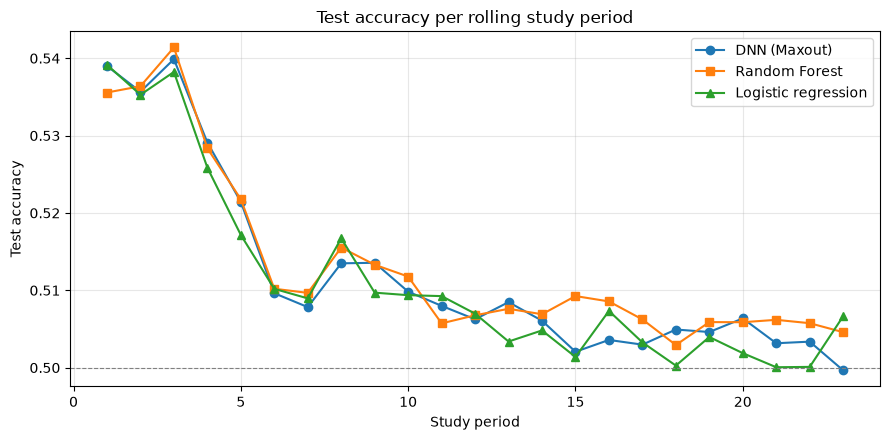

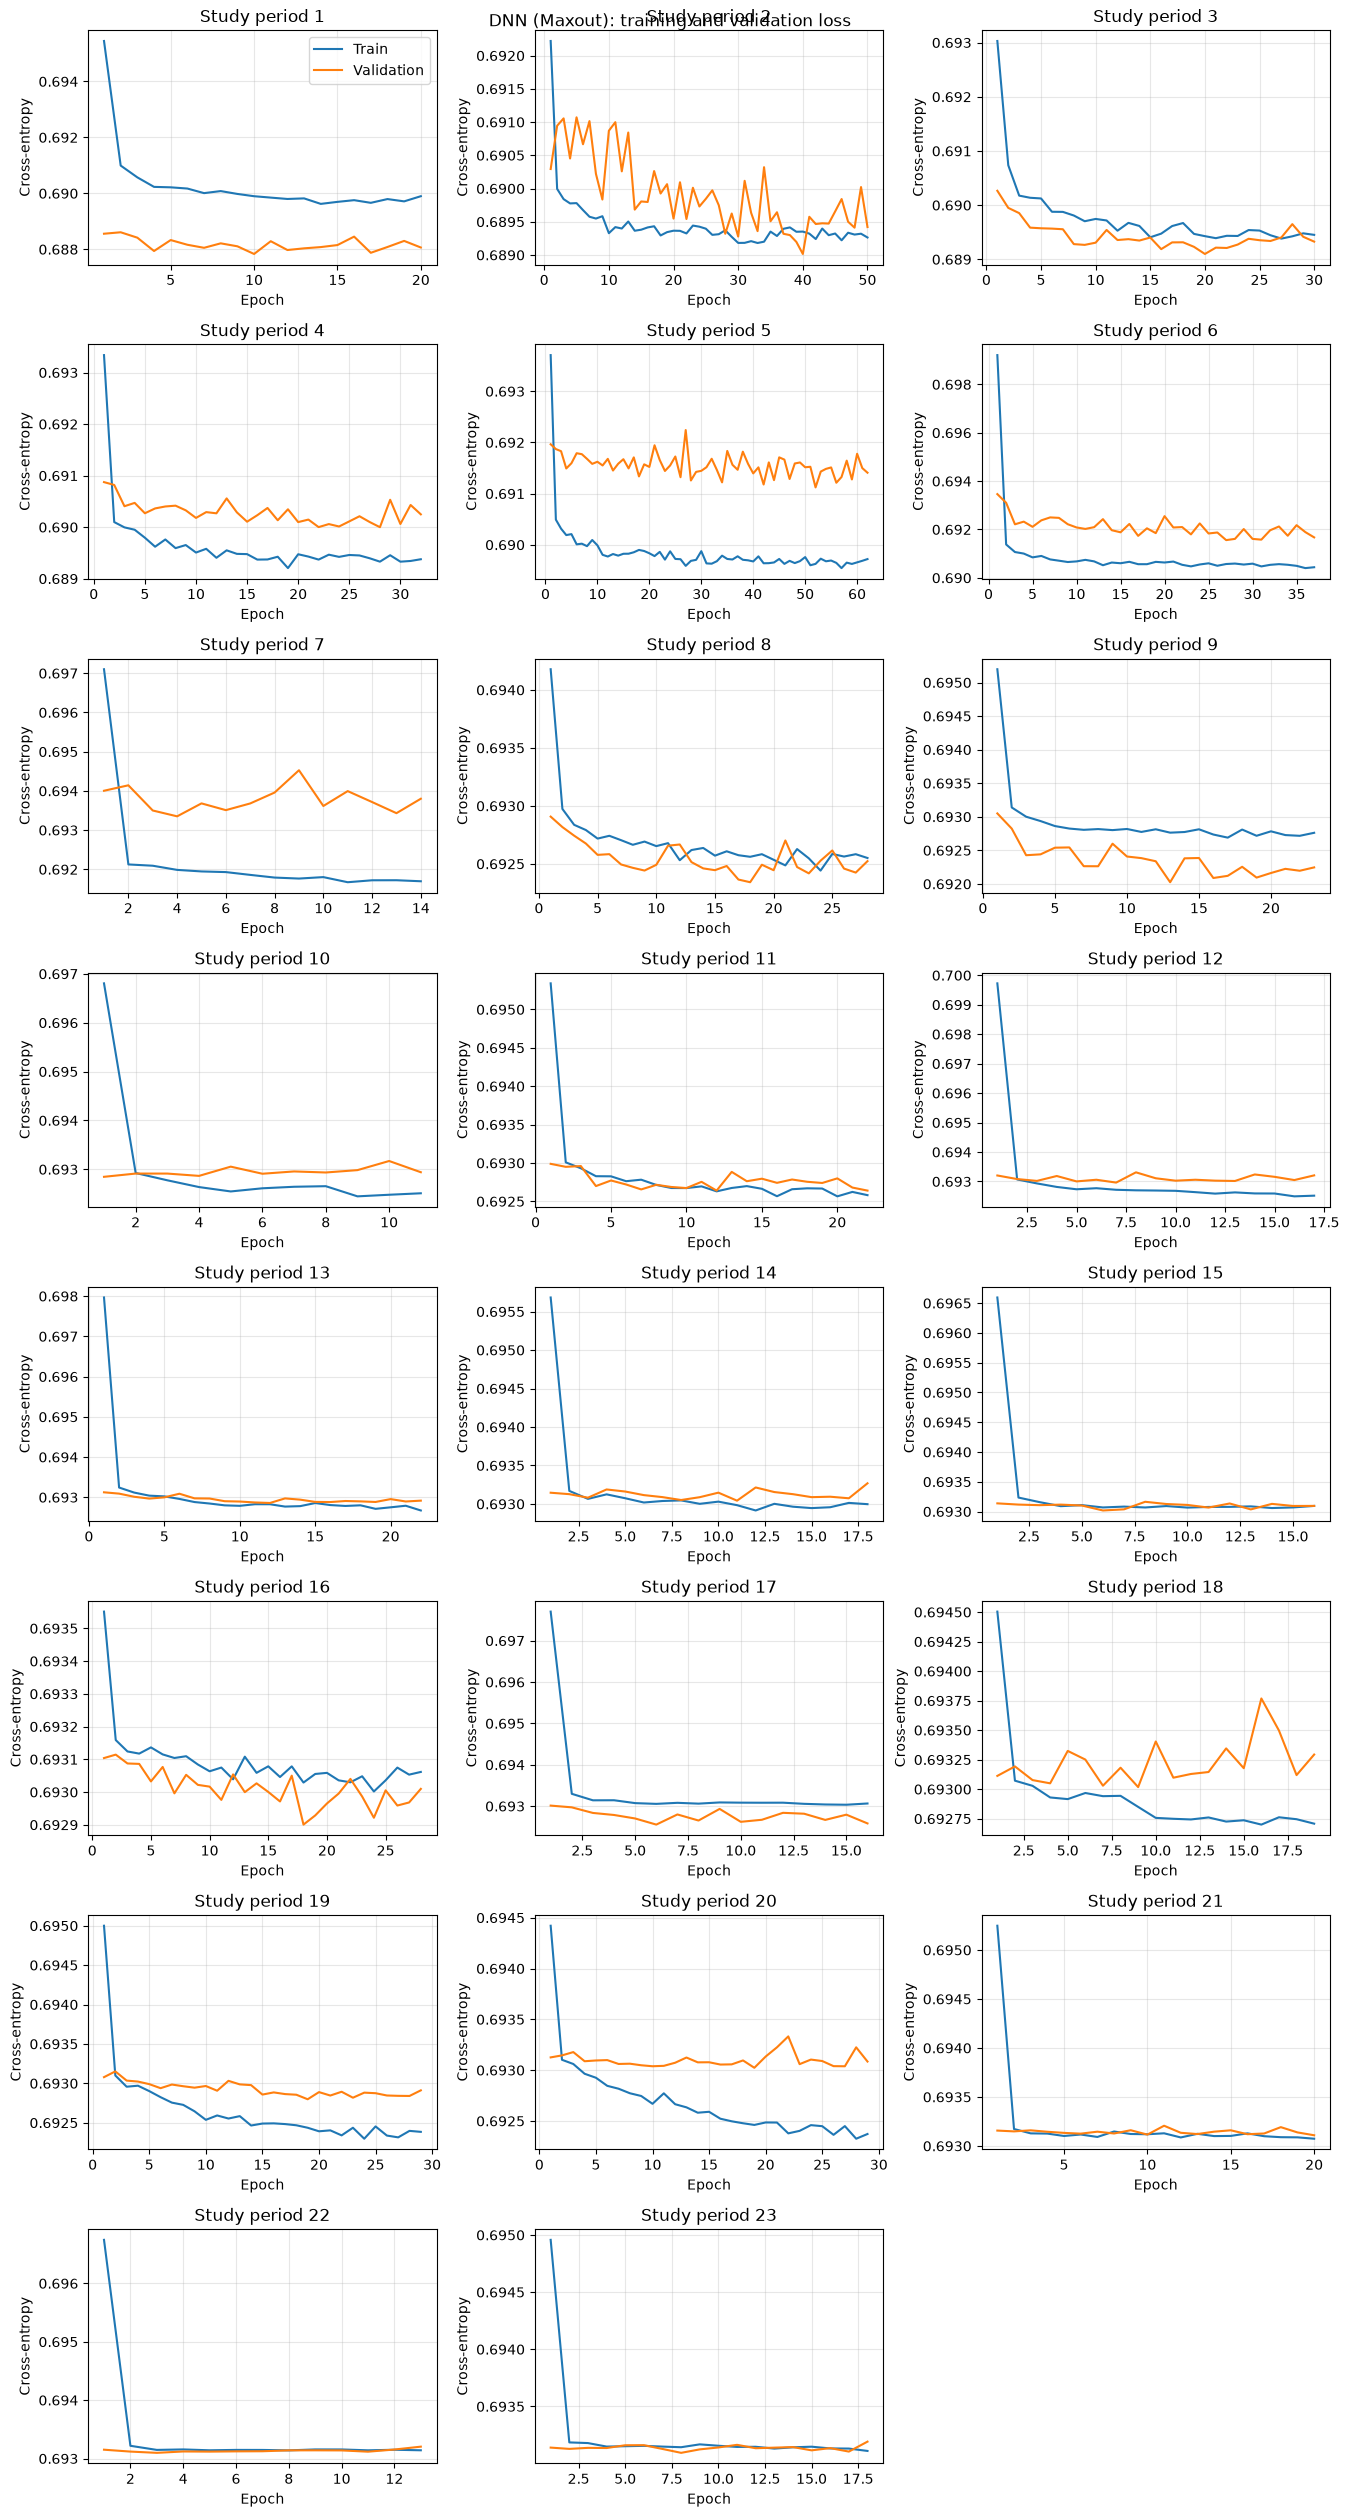

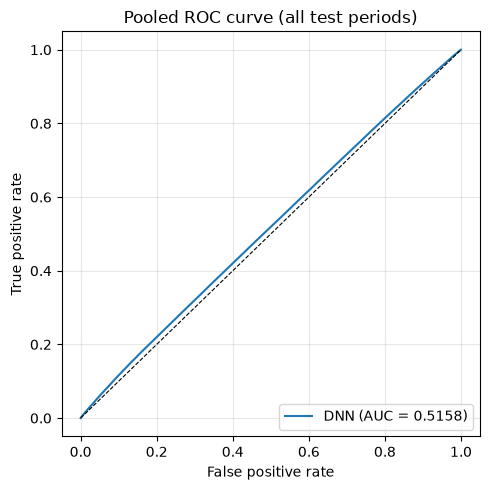

In [12]:
# 1. Test accuracy per study period: DNN vs RF vs LR (where available)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(dnn_periods["study_period"], dnn_periods["test_acc"], marker="o", label="DNN (Maxout)")
for path, label, marker in [(RESULTS_DIR / "rf_rolling_all_periods_summary.csv", "Random Forest", "s"),
                            (RESULTS_DIR / "rolling_all_periods_summary.csv", "Logistic regression", "^")]:
    if path.exists():
        s = pd.read_csv(path)
        ax.plot(s["study_period"], s["test_acc"], marker=marker, label=label)
ax.axhline(0.5, color="grey", linestyle="--", linewidth=0.8)
ax.set_xlabel("Study period")
ax.set_ylabel("Test accuracy")
ax.set_title("Test accuracy per rolling study period")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "dnn_rolling_accuracy.png", dpi=150)
plt.show()

# 2. Training and validation loss per study period
periods = sorted(dnn_histories["study_period"].unique())
ncols = min(3, len(periods))
nrows = int(np.ceil(len(periods) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3.2 * nrows), squeeze=False)
for ax, p in zip(axes.flat, periods):
    h = dnn_histories[dnn_histories["study_period"] == p]
    ax.plot(h["epoch"], h["train_loss"], label="Train")
    ax.plot(h["epoch"], h["val_loss"], label="Validation")
    ax.set_title(f"Study period {p}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Cross-entropy")
    ax.grid(alpha=0.3)
for ax in list(axes.flat)[len(periods):]:
    ax.set_visible(False)
axes.flat[0].legend()
fig.suptitle("DNN (Maxout): training and validation loss")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "dnn_loss_curves.png", dpi=150)
plt.show()

# 3. Pooled ROC curve
fpr, tpr, _ = roc_curve(y_te, p_te)
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(fpr, tpr, label=f"DNN (AUC = {pooled['roc_auc']:.4f})")
ax.plot([0, 1], [0, 1], "k--", linewidth=0.8)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("Pooled ROC curve (all test periods)")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "dnn_roc_curve.png", dpi=150)
plt.show()
